In [52]:
!pip install streamlit pandas numpy matplotlib seaborn plotly


In [53]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [54]:
df = pd.read_csv("E-commerce Customer Behavior Dataset.csv")

In [55]:
df.head()

,Customer ID,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase,Satisfaction Level
0,101,Female,29,New York,Gold,1120.20,14,4.6,True,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,True,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,True,55,Unsatisfied


In [56]:
df.shape

(350, 11)

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               350 non-null    int64  
 1   Gender                    350 non-null    object 
 2   Age                       350 non-null    int64  
 3   City                      350 non-null    object 
 4   Membership Type           350 non-null    object 
 5   Total Spend               350 non-null    float64
 6   Items Purchased           350 non-null    int64  
 7   Average Rating            350 non-null    float64
 8   Discount Applied          350 non-null    bool   
 9   Days Since Last Purchase  350 non-null    int64  
 10  Satisfaction Level        348 non-null    object 
dtypes: bool(1), float64(2), int64(4), object(4)
memory usage: 27.8+ KB


Checking for null values

In [58]:
df.isnull().sum()

,0
Customer ID,0
Gender,0
Age,0
City,0
Membership Type,0
Total Spend,0
Items Purchased,0
Average Rating,0
Discount Applied,0
Days Since Last Purchase,0


In [59]:
df[df["Satisfaction Level"].isnull()]

,Customer ID,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase,Satisfaction Level
71,172,Female,37,Houston,Bronze,420.8,7,3.1,False,21,NaN
143,244,Female,37,Houston,Bronze,430.8,7,3.4,False,23,NaN


In [60]:
df["Satisfaction Level"].value_counts()

,count
Satisfaction Level,
Satisfied,125
Unsatisfied,116
Neutral,107


In [61]:
df["Satisfaction Level"].fillna("Satisfied", inplace = True)

In [62]:
df.isnull().sum()

,0
Customer ID,0
Gender,0
Age,0
City,0
Membership Type,0
Total Spend,0
Items Purchased,0
Average Rating,0
Discount Applied,0
Days Since Last Purchase,0


In [63]:
df.duplicated().sum()

np.int64(0)

In [64]:
df.describe()

,Customer ID,Age,Total Spend,Items Purchased,Average Rating,Days Since Last Purchase
count,350.000000,350.000000,350.000000,350.000000,350.000000,350.000000
mean,275.500000,33.597143,845.381714,12.600000,4.019143,26.588571
std,101.180532,4.870882,362.058695,4.155984,0.580539,13.440813
min,101.000000,26.000000,410.800000,7.000000,3.000000,9.000000
25%,188.250000,30.000000,502.000000,9.000000,3.500000,15.000000
50%,275.500000,32.500000,775.200000,12.000000,4.100000,23.000000
75%,362.750000,37.000000,1160.600000,15.000000,4.500000,38.000000
max,450.000000,43.000000,1520.100000,21.000000,4.900000,63.000000


Observation 1: Age
Customer ages range from 26 to 43 years, with an average age of 33.6 years. The median age is 32.5 years, indicating that most customers belong to the young-to-middle-age group.
Observation 2: Total Spend
Customer spending ranges from 410.8 to 1520.1, with an average spending of 845.4. The large difference between the minimum and maximum values indicates substantial variation in purchasing behavior among customers.
Observation 3: Items Purchased
Customers purchase between 7 and 21 items, with an average of 12.6 items per customer. The median value of 12 suggests a balanced distribution of purchase quantities.
Observation 4: Average Rating
Customer ratings range from 3.0 to 4.9, with an average rating of 4.02. This indicates that overall customer satisfaction is generally positive.
Observation 5: Days Since Last Purchase
Days since last purchase range from 9 to 63 days, with an average of 26.6 days. This suggests that most customers make purchases within approximately one month of their previous transaction.

In [65]:
df.describe(include="object")

,Gender,City,Membership Type,Satisfaction Level
count,350,350,350,350
unique,2,6,3,3
top,Female,New York,Gold,Satisfied
freq,175,59,117,127


Finding Outliers using Box Plot

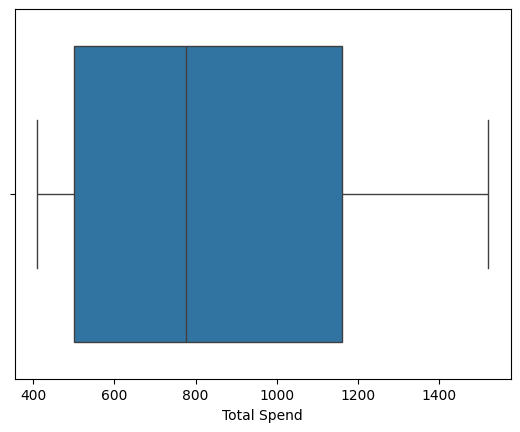

In [66]:
sns.boxplot(x=df["Total Spend"])
plt.show()

Observation:
No outliers were detected in the Total Spend column. All customer spending values fall within the expected range.




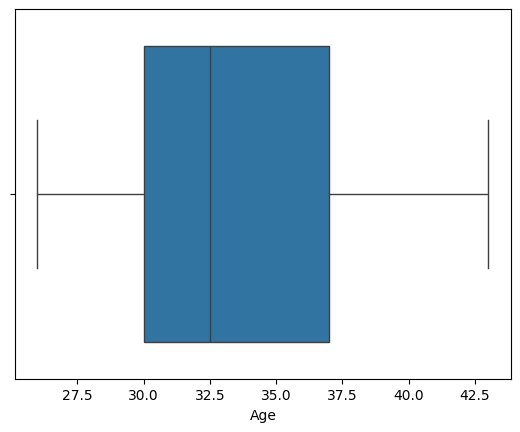

In [67]:
sns.boxplot(x=df["Age"])
plt.show()

Observation - No outliers were detected in the Age column. Customer ages fall within a reasonable range (26–43 years).

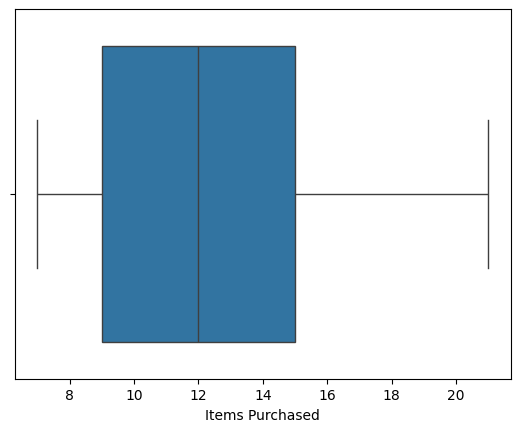

In [68]:
sns.boxplot(x=df["Items Purchased"])
plt.show()

Observation - No outliers were detected in the Items Purchased column. The number of items purchased ranges from 7 to 21 and falls within a reasonable range

In [69]:
df["Gender"].value_counts()

,count
Gender,
Female,175
Male,175


Observation - The dataset contains an equal number of male and female customers, indicating a balanced gender distribution.

In [70]:
df.groupby("Gender")["Total Spend"].mean()

,Total Spend
Gender,
Female,703.828571
Male,986.934857


Observation: Male customers have a higher average spending (986.93) compared to female customers (703.83), indicating that male customers contribute more revenue on average.

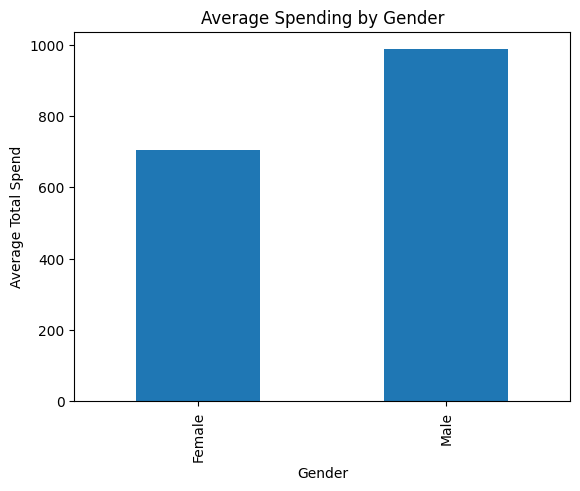

In [71]:
df.groupby("Gender")["Total Spend"].mean().plot(kind="bar")
plt.title("Average Spending by Gender")
plt.ylabel("Average Total Spend")
plt.show()

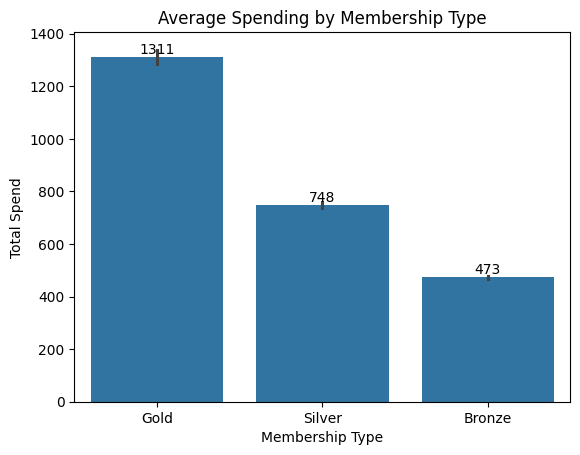

In [72]:
ax = sns.barplot(data=df, x="Membership Type", y="Total Spend")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Average Spending by Membership Type")
plt.show()

Observation : Gold members have the highest average spending which is 1311, followed by Silver members with 748, while Bronze members spend the least which is 473. This indicates that higher membership tiers are associated with greater customer spending.

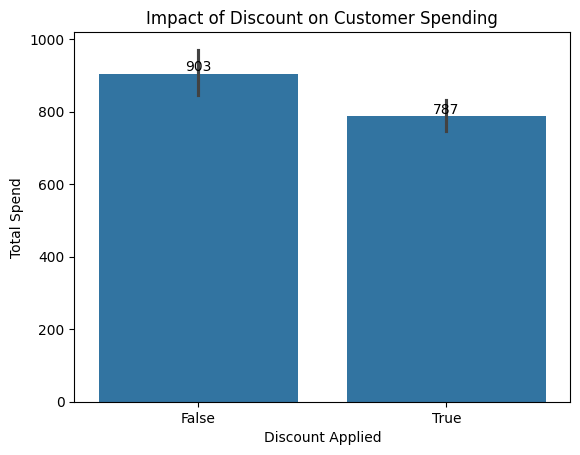

In [73]:
ax = sns.barplot(data=df, x="Discount Applied", y="Total Spend")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Impact of Discount on Customer Spending")
plt.show()

Observation: Customers who did not receive discounts spent more on average than those who received discounts. This suggests that discounts alone may not be the primary driver of customer spending and the current discount strategy may need further evaluation.

Correlation Heatmap

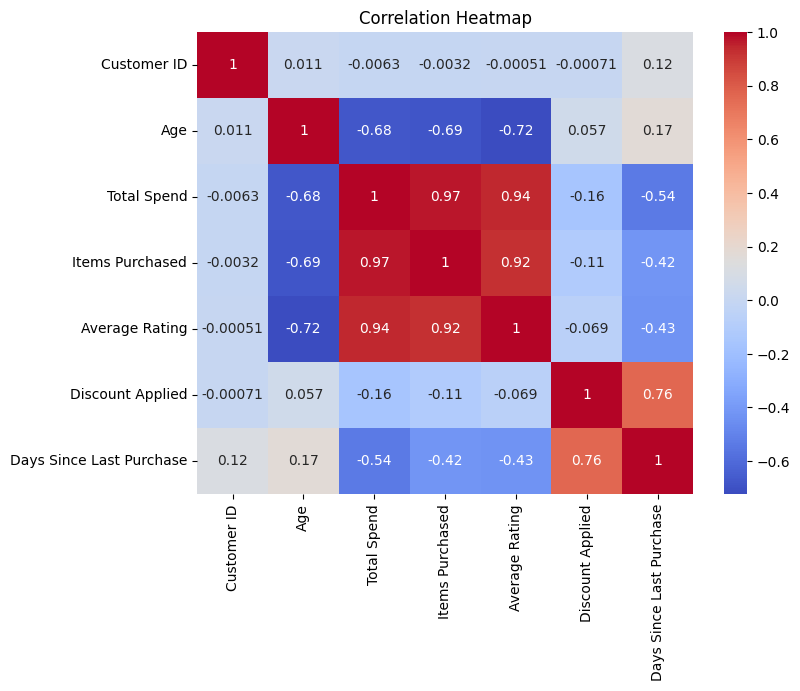

In [74]:
plt.figure(figsize=(8,6))

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

Observation : The correlation analysis reveals strong positive relationships between Total Spend, Items Purchased, and Average Rating. Customers who purchase more items tend to spend more and provide higher ratings. Additionally, a strong positive correlation between Discount Applied and Days Since Last Purchase suggests that discounts are frequently offered to customers who have not made recent purchases.

Multivariate Analysis

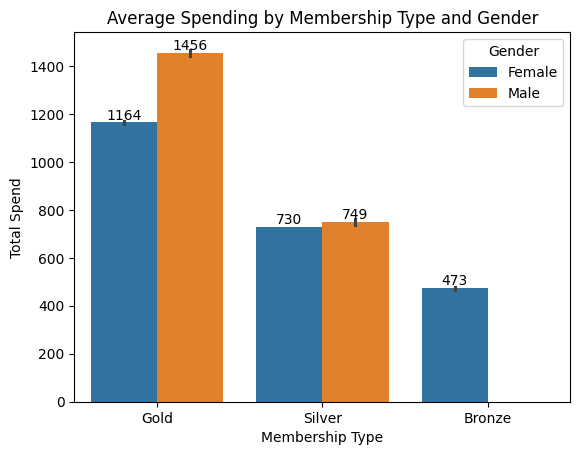

In [75]:
ax = sns.barplot(
    data=df,
    x="Membership Type",
    y="Total Spend",
    hue="Gender"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Average Spending by Membership Type and Gender")
plt.show()

Observation : Gold Male customers are the highest-spending customer segment, with an average spend of 1456, followed by Gold Female customers at 1164. Silver customers show similar spending patterns across genders, while Bronze membership consists only of female customers with the lowest average spending. This indicates that Gold members, particularly males, contribute the highest revenue to the business.

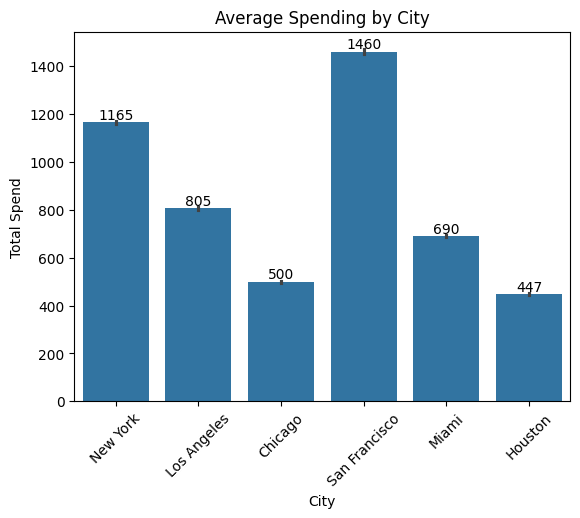

In [76]:
ax = sns.barplot(
    data=df,
    x="City",
    y="Total Spend"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Average Spending by City")
plt.xticks(rotation=45)
plt.show()

Observation : San Francisco customers have the highest average spending (1460), followed by New York customers (1165). Houston customers have the lowest average spending (447). This indicates that San Francisco and New York are the most valuable markets, while Houston generates the least revenue per customer.

Histogram

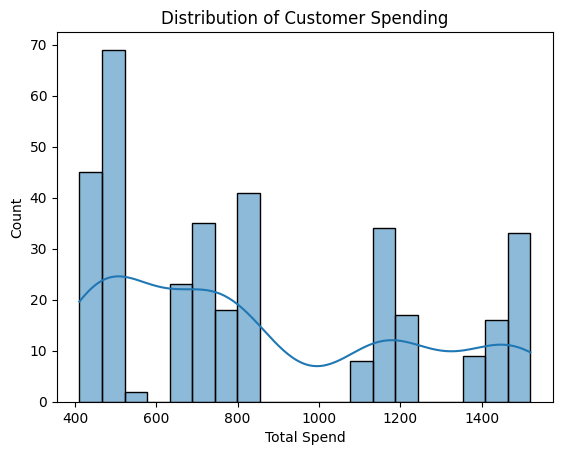

In [77]:
sns.histplot(df["Total Spend"], bins=20, kde=True)
plt.title("Distribution of Customer Spending")
plt.show()

Observation : The histogram shows that customer spending is spread across multiple spending ranges rather than being concentrated in a single range. This indicates the presence of different customer segments, including low-, medium-, and high-spending customers. The wide distribution of spending suggests diverse purchasing behaviors among customers

Pie Chart

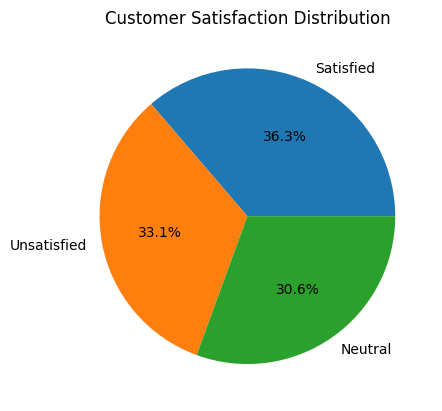

In [78]:
df["Satisfaction Level"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)
plt.title("Customer Satisfaction Distribution")
plt.ylabel("")
plt.show()

Observation - Satisfied customers represent the largest group (36.3%) of the customer base, followed by Unsatisfied customers (33.1%) and Neutral customers (30.6%). The distribution is relatively balanced, indicating that while customer satisfaction is slightly positive overall, a significant proportion of customers remain neutral or dissatisfied, highlighting opportunities for improving customer experience.

Stacked Bar Chart

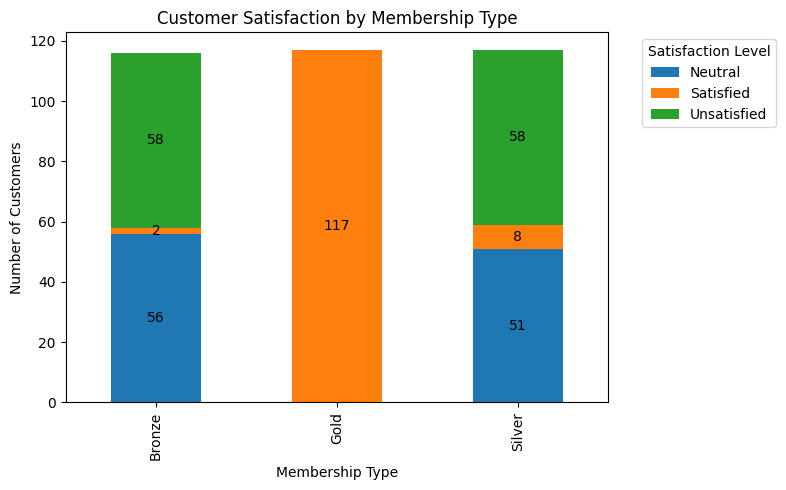

In [79]:
satisfaction_by_membership = pd.crosstab(
    df["Membership Type"],
    df["Satisfaction Level"]
)

ax = satisfaction_by_membership.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

# Add labels inside each colored section and hide zeros
for container in ax.containers:
    labels = [f"{int(v)}" if v > 0 else "" for v in container.datavalues]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center"
    )

plt.title("Customer Satisfaction by Membership Type")
plt.xlabel("Membership Type")
plt.ylabel("Number of Customers")

plt.legend(
    title="Satisfaction Level",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Observation : Gold members exhibit the highest satisfaction levels, with all Gold customers classified as satisfied. In contrast, Bronze and Silver memberships contain a large proportion of neutral and unsatisfied customers. This suggests that premium membership benefits may significantly improve customer satisfaction and retention.

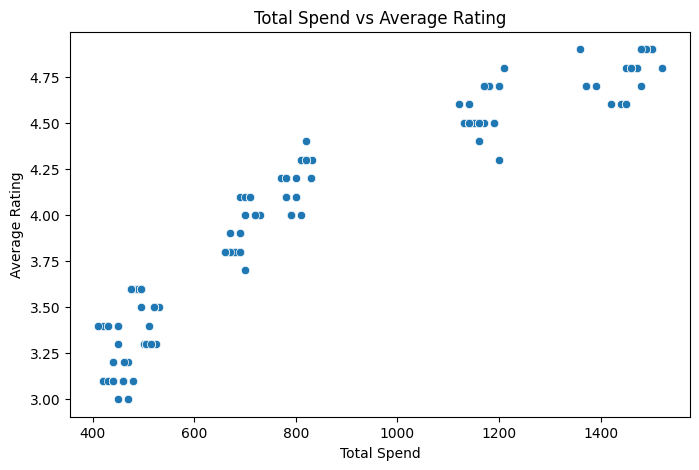

In [80]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Total Spend",
    y="Average Rating"
)

plt.title("Total Spend vs Average Rating")
plt.xlabel("Total Spend")
plt.ylabel("Average Rating")

plt.show()

Observation :
A strong positive relationship exists between Total Spend and Average Rating. Customers who spend more tend to provide higher ratings, indicating that increased spending is associated with greater customer satisfaction.

In [81]:
from sqlalchemy import create_engine

engine = create_engine("sqlite:///customer_data.db")

In [82]:
df.to_sql(
    "customers",
    engine,
    if_exists="replace",
    index=False
)

350

In [83]:
query = "SELECT * FROM customers LIMIT 5"

pd.read_sql(query, engine)

,Customer ID,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase,Satisfaction Level
0,101,Female,29,New York,Gold,1120.20,14,4.6,1,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,0,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,1,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,0,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,1,55,Unsatisfied


Top Spending Customers Who Have Not Purchased Recently

In [84]:
query = """
SELECT

[Customer ID],
    [Membership Type],
    [Total Spend],
    [Average Rating],
    [Days Since Last Purchase]
FROM customers
WHERE [Total Spend] >
(
    SELECT AVG([Total Spend])
    FROM customers
)
AND [Days Since Last Purchase] > 30
ORDER BY [Total Spend] DESC
"""

pd.read_sql(query, engine)

,Customer ID,Membership Type,Total Spend,Average Rating,Days Since Last Purchase
0,382,Gold,1160.6,4.5,31
1,406,Gold,1160.6,4.5,33
2,430,Gold,1160.6,4.5,35
3,394,Gold,1140.6,4.5,32
4,418,Gold,1140.6,4.5,34
5,442,Gold,1140.6,4.5,36


Insight : The query identifies above-average spending customers that have not made a purchase in more than 30 days. These customers may be suitable targets for retention campaigns and personalized offers.

High-Spending Customers with Below-Average Satisfaction

In [85]:
query = """
SELECT
    [Customer ID],
    [Membership Type],
    [Total Spend],
    [Average Rating]
FROM customers
WHERE [Total Spend] >
(
    SELECT AVG([Total Spend])
    FROM customers
)
AND [Average Rating] <
(
    SELECT AVG([Average Rating])
    FROM customers
)
ORDER BY [Total Spend] DESC
"""

pd.read_sql(query, engine)

,Customer ID,Membership Type,Total Spend,Average Rating


Insight: The query identifies customers who contribute above-average revenue but report below-average satisfaction.

Customers Spending More Than Their Membership Average

In [86]:
query = """
SELECT
    [Customer ID],
    [Membership Type],
    [Total Spend]
FROM customers c
WHERE [Total Spend] >
(
    SELECT AVG([Total Spend])
    FROM customers
    WHERE [Membership Type] = c.[Membership Type]
)
ORDER BY [Total Spend] DESC
"""

pd.read_sql(query, engine)

,Customer ID,Membership Type,Total Spend
0,110,Gold,1520.10
1,128,Gold,1500.10
2,158,Gold,1500.10
3,188,Gold,1500.10
4,218,Gold,1500.10
...,...,...,...
171,318,Bronze,480.25
172,372,Bronze,475.25
173,396,Bronze,475.25
174,420,Bronze,475.25


Insight: The query identifies customers whose spending exceeds the average spending of their respective membership group. These customers represent top performers within their segment and may be suitable candidates for loyalty rewards and personalized engagement strategies.

Customer Satisfaction Rate by City

In [87]:
query = """
SELECT
    City,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN [Satisfaction Level] = 'Satisfied' THEN 1 ELSE 0 END) AS Satisfied_Customers,
    ROUND(
        100.0 * SUM(CASE WHEN [Satisfaction Level] = 'Satisfied' THEN 1 ELSE 0 END)
        / COUNT(*),
        2
    ) AS Satisfaction_Percentage
FROM customers
GROUP BY City
ORDER BY Satisfaction_Percentage DESC
"""

pd.read_sql(query, engine)

,City,Total_Customers,Satisfied_Customers,Satisfaction_Percentage
0,San Francisco,58,58,100.00
1,New York,59,59,100.00
2,Los Angeles,59,8,13.56
3,Houston,58,2,3.45
4,Miami,58,0,0.00
5,Chicago,58,0,0.00


Insight: The analysis ranks cities based on the percentage of satisfied customers. This helps identify locations with the strongest customer experience and those requiring service improvements.

Percentage Contribution of Membership Tiers to Total Revenue

In [88]:
query = """
SELECT
    [Membership Type],
    ROUND(SUM([Total Spend]), 2) AS Total_Revenue,
    ROUND(
        100.0 * SUM([Total Spend]) /
        (SELECT SUM([Total Spend]) FROM customers),
        2
    ) AS Revenue_Percentage
FROM customers
GROUP BY [Membership Type]
ORDER BY Total_Revenue DESC
"""

pd.read_sql(query, engine)

,Membership Type,Total_Revenue,Revenue_Percentage
0,Gold,153403.9,51.85
1,Silver,87566.6,29.59
2,Bronze,54913.1,18.56


This query calculates the total revenue generated by each membership tier and its percentage contribution to overall company revenue. It helps identify which membership segment has the greatest financial impact on the business and where customer retention efforts should be prioritized.

## Business Recommendations

Based on the data analysis, the following business recommendations are proposed to enhance customer experience, optimize spending, and improve overall business performance:

### 1. Focus on High-Value Segments
*   **Gold Members (especially Male Gold customers):** These customers are the highest spenders and show 100% satisfaction. Develop exclusive loyalty programs, offer early access to new products, and provide highly personalized communications to maintain their engagement and loyalty. Consider creating special campaigns or product lines tailored to their preferences.
*   **Customers in San Francisco and New York:** These cities exhibit both high average spending and 100% customer satisfaction. Increase marketing efforts and potentially expand service offerings in these regions to capitalize on their strong performance and build deeper customer relationships.

### 2. Improve Satisfaction and Engagement for Mid-Tier and Low-Tier Members
*   **Bronze and Silver Members:** A significant proportion of these members are either neutral or unsatisfied. It is crucial to investigate the underlying reasons for their dissatisfaction. Implement feedback mechanisms (surveys, focus groups) to gather insights. Consider:
    *   **Silver Members:** Introduce enhanced benefits or incentives to encourage upgrades to the Gold tier.
    *   **Bronze Members:** Improve customer service interactions and offer personalized benefits to elevate their experience and increase spending.

### 3. Re-evaluate Discount Strategy
*   The analysis suggests that customers who did not receive discounts spent more on average than those who did. This indicates that price-based discounts alone might not be the most effective driver of spending. Explore alternative value-added promotions such as loyalty points, free shipping, exclusive content, or bundled offers that provide perceived value beyond mere price reduction. Discounts could be more effectively utilized as a strategic re-engagement tool rather than a general sales tactic.

### 4. Implement Targeted Retention Campaigns
*   **Identify and Re-engage At-Risk High Spenders:** The query for "Top Spending Customers Who Have Not Purchased Recently" identifies above-average spending customers who haven't made a purchase in over 30 days. These customers are prime candidates for targeted retention campaigns. Reach out with personalized incentives, special offers, or a "we miss you" campaign to encourage their return and prevent churn.

### 5. Address Low Customer Satisfaction in Specific Cities
*   **Urgent Action for Los Angeles, Miami, Houston, and Chicago:** These cities show alarmingly low or zero customer satisfaction rates. This is a critical area that requires immediate attention. Conduct in-depth investigations, such as customer service audits, localized customer satisfaction surveys, and competitive analysis within these regions, to understand and rectify the root causes of dissatisfaction. Improving satisfaction in these areas could unlock significant revenue potential.

### 6. Leverage Data for Continuous Personalization
*   Given the observed diversity in spending behaviors, membership types, and satisfaction levels across different customer segments, continue to utilize data-driven insights. Develop and refine personalized marketing campaigns, product recommendations, and customer service strategies to cater to individual customer needs and preferences, thereby fostering stronger customer relationships and maximizing lifetime value.

## Conclusion

This project provided a comprehensive analysis of e-commerce customer behavior, leveraging various data exploration and visualization techniques to uncover valuable insights. We identified distinct customer segments based on spending habits, membership types, and satisfaction levels. Key findings highlighted the significant revenue contribution of Gold members, particularly males, and the superior performance of customers in San Francisco and New York.

Conversely, the analysis exposed areas of concern, such as the lower satisfaction among Bronze and Silver members and alarmingly low satisfaction rates in cities like Los Angeles, Miami, Houston, and Chicago. The data also indicated that the current discount strategy might not be driving optimal spending.

The business recommendations derived from this analysis emphasize a data-driven approach to enhancing customer experience and maximizing revenue. By focusing on high-value segments, addressing dissatisfaction in mid-tier and low-tier memberships, refining the discount strategy, implementing targeted retention campaigns, and urgently addressing city-specific satisfaction issues, the business can foster stronger customer relationships, improve loyalty, and achieve sustainable growth. Continuous monitoring and personalization based on these insights will be crucial for long-term success.